## 3.000 Genes por MAD

In [3]:
import os
import numpy as np
import pandas as pd
from scipy.spatial.distance import mahalanobis
from sklearn.decomposition import PCA

def run_pipeline_from_vst_csv(
    csv_path: str = r"data/processed/df_vst.csv",
    threshold_sd: float = 3.0,
    pca_qc_components: int = 5,
    n_top_genes_mad: int = 3000,
    n_components_pca_final: int = 50
):
    """
    Carrega a base VST em CSV (Linhas = Amostras, Colunas = Genes),
    executa o QC de amostras (Detecção de Outliers via Mahalanobis),
    aplica a seleção de feições por MAD e reduz para 50 componentes principais.
    """
    # 1. Carregamento dos dados (Assume primeira coluna como ID da amostra)
    print(f"Carregando a base VST de: {csv_path} ...")
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Arquivo não encontrado no caminho: {csv_path}")
        
    df_vst = pd.read_csv(csv_path, index_col=0)
    print(f"Dimensão da matriz VST original: {df_vst.shape[0]} amostras x {df_vst.shape[1]} genes")

    # =========================================================================
    # ETAPA 1: CONTROLE DE QUALIDADE (QC) - DETECÇÃO DE OUTLIERS DE AMOSTRAS
    # =========================================================================
    # Como as amostras já estão nas linhas, pegamos diretamente a matriz de valores
    X = df_vst.values
    sample_names = df_vst.index.tolist()

    # PCA inicial leve para estabilizar o cálculo multivariado das distâncias
    pca_qc = PCA(n_components=pca_qc_components, random_state=42)
    X_pca_qc = pca_qc.fit_transform(X)

    # Cálculo da Distância de Mahalanobis em relação ao centroide da coorte
    mean_vector = np.mean(X_pca_qc, axis=0)
    cov_matrix = np.cov(X_pca_qc, rowvar=False)
    
    # Regularização leve para prevenir matrizes singulares
    cov_matrix += np.eye(cov_matrix.shape[0]) * 1e-6
    inv_cov_matrix = np.linalg.inv(cov_matrix)

    distances = np.array([
        mahalanobis(sample, mean_vector, inv_cov_matrix) 
        for sample in X_pca_qc
    ])

    # Filtragem estatística (Z-Score das distâncias <= threshold_sd)
    mean_dist = np.mean(distances)
    std_dist = np.std(distances)
    cutoff = mean_dist + (threshold_sd * std_dist)

    is_valid = distances <= cutoff
    passed_samples = np.array(sample_names)[is_valid]
    outliers = np.array(sample_names)[~is_valid]

    print("\n" + "="*50)
    print(" RELATÓRIO DO CONTROLE DE QUALIDADE (QC) ")
    print("="*50)
    print(f"Total de amostras analisadas : {len(sample_names)}")
    print(f"Amostras APROVADAS           : {len(passed_samples)}")
    print(f"Amostras OUTLIERS (descartadas): {len(outliers)}")
    if len(outliers) > 0:
        print(f"IDs das amostras descartadas : {list(outliers)}")
    print("="*50 + "\n")

    # Filtra as linhas mantendo apenas as amostras aprovadas no QC
    df_vst_qc = df_vst.loc[passed_samples]

    # =========================================================================
    # ETAPA 2: SELEÇÃO DE ATRIBUTOS VIA MAD (3000 GENES MAIS VARIÁVEIS)
    # =========================================================================
    print(f"Calculando o MAD para selecionar os {n_top_genes_mad} genes mais variáveis...")
    
    # MAD = mediana(|x - mediana(x)|) por gene (eixo 0 = ao longo das amostras)
    mad_scores = df_vst_qc.apply(
        lambda col: np.median(np.abs(col - np.median(col))), 
        axis=0
    )
    
    top_genes = mad_scores.nlargest(n_top_genes_mad).index
    df_mad = df_vst_qc[top_genes]
    print(f"Matriz filtrada por MAD: {df_mad.shape[0]} amostras x {df_mad.shape[1]} genes")

    # =========================================================================
    # ETAPA 3: PCA FINAL (50 COMPONENTES) PARA ENTRADA NO PaCMAP
    # =========================================================================
    print(f"Aplicando PCA final para extrair os {n_components_pca_final} componentes principais...")
    
    X_mad = df_mad.values
    
    pca_final = PCA(n_components=n_components_pca_final, random_state=42)
    X_pca_50 = pca_final.fit_transform(X_mad)
    
    # DataFrame final com 50 PCs
    pc_cols = [f"PC_{i+1}" for i in range(n_components_pca_final)]
    df_pca_50 = pd.DataFrame(X_pca_50, index=df_mad.index, columns=pc_cols)
    
    print(f"Proporção de variância explicada acumulada (50 PCs): {np.sum(pca_final.explained_variance_ratio_):.4f}")
    print("Processamento concluído com sucesso!")
    
    return df_pca_50

# Execução do script:
if __name__ == "__main__":
    df_pacmap_input = run_pipeline_from_vst_csv(csv_path=r"D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv")

Carregando a base VST de: D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv ...
Dimensão da matriz VST original: 970 amostras x 22896 genes

 RELATÓRIO DO CONTROLE DE QUALIDADE (QC) 
Total de amostras analisadas : 970
Amostras APROVADAS           : 964
Amostras OUTLIERS (descartadas): 6
IDs das amostras descartadas : [np.str_('TCGA-A2-A3XV'), np.str_('TCGA-A7-A56D'), np.str_('TCGA-AO-A0JC'), np.str_('TCGA-E9-A54Y'), np.str_('TCGA-LL-A6FR'), np.str_('TCGA-V7-A7HQ')]

Calculando o MAD para selecionar os 3000 genes mais variáveis...
Matriz filtrada por MAD: 964 amostras x 3000 genes
Aplicando PCA final para extrair os 50 componentes principais...
Proporção de variância explicada acumulada (50 PCs): 0.6445
Processamento concluído com sucesso!


## 5.000 Genes por MAD

In [4]:
import os
import numpy as np
import pandas as pd
from scipy.spatial.distance import mahalanobis
from sklearn.decomposition import PCA

def run_pipeline_from_vst_csv(
    csv_path: str = r"data/processed/df_vst.csv",
    threshold_sd: float = 3.0,
    pca_qc_components: int = 5,
    n_top_genes_mad: int = 5000,
    n_components_pca_final: int = 50
):
    """
    Carrega a base VST em CSV (Linhas = Amostras, Colunas = Genes),
    executa o QC de amostras (Detecção de Outliers via Mahalanobis),
    aplica a seleção de feições por MAD e reduz para 50 componentes principais.
    """
    # 1. Carregamento dos dados (Assume primeira coluna como ID da amostra)
    print(f"Carregando a base VST de: {csv_path} ...")
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Arquivo não encontrado no caminho: {csv_path}")
        
    df_vst = pd.read_csv(csv_path, index_col=0)
    print(f"Dimensão da matriz VST original: {df_vst.shape[0]} amostras x {df_vst.shape[1]} genes")

    # =========================================================================
    # ETAPA 1: CONTROLE DE QUALIDADE (QC) - DETECÇÃO DE OUTLIERS DE AMOSTRAS
    # =========================================================================
    # Como as amostras já estão nas linhas, pegamos diretamente a matriz de valores
    X = df_vst.values
    sample_names = df_vst.index.tolist()

    # PCA inicial leve para estabilizar o cálculo multivariado das distâncias
    pca_qc = PCA(n_components=pca_qc_components, random_state=42)
    X_pca_qc = pca_qc.fit_transform(X)

    # Cálculo da Distância de Mahalanobis em relação ao centroide da coorte
    mean_vector = np.mean(X_pca_qc, axis=0)
    cov_matrix = np.cov(X_pca_qc, rowvar=False)
    
    # Regularização leve para prevenir matrizes singulares
    cov_matrix += np.eye(cov_matrix.shape[0]) * 1e-6
    inv_cov_matrix = np.linalg.inv(cov_matrix)

    distances = np.array([
        mahalanobis(sample, mean_vector, inv_cov_matrix) 
        for sample in X_pca_qc
    ])

    # Filtragem estatística (Z-Score das distâncias <= threshold_sd)
    mean_dist = np.mean(distances)
    std_dist = np.std(distances)
    cutoff = mean_dist + (threshold_sd * std_dist)

    is_valid = distances <= cutoff
    passed_samples = np.array(sample_names)[is_valid]
    outliers = np.array(sample_names)[~is_valid]

    print("\n" + "="*50)
    print(" RELATÓRIO DO CONTROLE DE QUALIDADE (QC) ")
    print("="*50)
    print(f"Total de amostras analisadas : {len(sample_names)}")
    print(f"Amostras APROVADAS           : {len(passed_samples)}")
    print(f"Amostras OUTLIERS (descartadas): {len(outliers)}")
    if len(outliers) > 0:
        print(f"IDs das amostras descartadas : {list(outliers)}")
    print("="*50 + "\n")

    # Filtra as linhas mantendo apenas as amostras aprovadas no QC
    df_vst_qc = df_vst.loc[passed_samples]

    # =========================================================================
    # ETAPA 2: SELEÇÃO DE ATRIBUTOS VIA MAD (5000 GENES MAIS VARIÁVEIS)
    # =========================================================================
    print(f"Calculando o MAD para selecionar os {n_top_genes_mad} genes mais variáveis...")
    
    # MAD = mediana(|x - mediana(x)|) por gene (eixo 0 = ao longo das amostras)
    mad_scores = df_vst_qc.apply(
        lambda col: np.median(np.abs(col - np.median(col))), 
        axis=0
    )
    
    top_genes = mad_scores.nlargest(n_top_genes_mad).index
    df_mad = df_vst_qc[top_genes]
    print(f"Matriz filtrada por MAD: {df_mad.shape[0]} amostras x {df_mad.shape[1]} genes")

    # =========================================================================
    # ETAPA 3: PCA FINAL (50 COMPONENTES) PARA ENTRADA NO PaCMAP
    # =========================================================================
    print(f"Aplicando PCA final para extrair os {n_components_pca_final} componentes principais...")
    
    X_mad = df_mad.values
    
    pca_final = PCA(n_components=n_components_pca_final, random_state=42)
    X_pca_50 = pca_final.fit_transform(X_mad)
    
    # DataFrame final com 50 PCs
    pc_cols = [f"PC_{i+1}" for i in range(n_components_pca_final)]
    df_pca_50 = pd.DataFrame(X_pca_50, index=df_mad.index, columns=pc_cols)
    
    print(f"Proporção de variância explicada acumulada (50 PCs): {np.sum(pca_final.explained_variance_ratio_):.4f}")
    print("Processamento concluído com sucesso!")
    
    return df_pca_50

# Execução do script:
if __name__ == "__main__":
    df_pacmap_input = run_pipeline_from_vst_csv(csv_path=r"D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv")

Carregando a base VST de: D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv ...
Dimensão da matriz VST original: 970 amostras x 22896 genes

 RELATÓRIO DO CONTROLE DE QUALIDADE (QC) 
Total de amostras analisadas : 970
Amostras APROVADAS           : 964
Amostras OUTLIERS (descartadas): 6
IDs das amostras descartadas : [np.str_('TCGA-A2-A3XV'), np.str_('TCGA-A7-A56D'), np.str_('TCGA-AO-A0JC'), np.str_('TCGA-E9-A54Y'), np.str_('TCGA-LL-A6FR'), np.str_('TCGA-V7-A7HQ')]

Calculando o MAD para selecionar os 5000 genes mais variáveis...
Matriz filtrada por MAD: 964 amostras x 5000 genes
Aplicando PCA final para extrair os 50 componentes principais...
Proporção de variância explicada acumulada (50 PCs): 0.6308
Processamento concluído com sucesso!


In [2]:
import os
import numpy as np
import pandas as pd
from scipy.spatial.distance import mahalanobis
from scipy.stats import median_abs_deviation
from sklearn.decomposition import PCA

def run_pipeline_from_vst_csv(
    csv_path: str = r"D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv",
    threshold_sd: float = 3.0,
    pca_qc_components: int = 5,
    n_top_genes_mad: int = 5000,
    n_components_pca_final: int = 50,
    output_dir: str = r"D:\Projetos Python\Mestrado\RBras\data\processed"
):
    print(f"Carregando a base VST de: {csv_path} ...")
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Arquivo não encontrado no caminho: {csv_path}")
        
    df_vst = pd.read_csv(csv_path, index_col=0)
    print(f"Dimensão da matriz VST original: {df_vst.shape[0]} amostras x {df_vst.shape[1]} genes")

    # =========================================================================
    # ETAPA 1: CONTROLE DE QUALIDADE (QC)
    # =========================================================================
    X = df_vst.values
    sample_names = df_vst.index.tolist()

    pca_qc = PCA(n_components=pca_qc_components, random_state=42)
    X_pca_qc = pca_qc.fit_transform(X)

    mean_vector = np.mean(X_pca_qc, axis=0)
    cov_matrix = np.cov(X_pca_qc, rowvar=False) + np.eye(pca_qc_components) * 1e-6
    inv_cov_matrix = np.linalg.inv(cov_matrix)

    distances = np.array([mahalanobis(sample, mean_vector, inv_cov_matrix) for sample in X_pca_qc])

    cutoff = np.mean(distances) + (threshold_sd * np.std(distances))
    passed_samples = np.array(sample_names)[distances <= cutoff]
    df_vst_qc = df_vst.loc[passed_samples]

    # =========================================================================
    # ETAPA 2: SELEÇÃO POR MAD (VETORIZADO VIA SCIPY)
    # =========================================================================
    print(f"Calculando o MAD para selecionar os {n_top_genes_mad} genes mais variáveis...")
    
    # Cálculo vetorizado do MAD ao longo do eixo das amostras (eixo 0)
    mad_values = median_abs_deviation(df_vst_qc.values, axis=0)
    mad_scores = pd.Series(mad_values, index=df_vst_qc.columns)
    
    top_genes = mad_scores.nlargest(n_top_genes_mad).index
    df_mad = df_vst_qc[top_genes]
    print(f"Matriz filtrada por MAD: {df_mad.shape[0]} amostras x {df_mad.shape[1]} genes")

    # =========================================================================
    # ETAPA 3: PCA FINAL (50 COMPONENTES)
    # =========================================================================
    print(f"Aplicando PCA final para extrair os {n_components_pca_final} componentes...")
    pca_final = PCA(n_components=n_components_pca_final, random_state=42)
    X_pca_50 = pca_final.fit_transform(df_mad.values)
    
    pc_cols = [f"PC_{i+1}" for i in range(n_components_pca_final)]
    df_pca_50 = pd.DataFrame(X_pca_50, index=df_mad.index, columns=pc_cols)
    print(f"Proporção de variância explicada acumulada: {np.sum(pca_final.explained_variance_ratio_):.4f}")

    # =========================================================================
    # ETAPA 4: SALVANDO A BASE PARA O OPTUNA
    # =========================================================================
    os.makedirs(output_dir, exist_ok=True)
    
    # Nome do arquivo incluindo o parâmetro dos genes
    file_prefix = f"df_pca_50_mad{n_top_genes_mad}"
    
    csv_out_path = os.path.join(output_dir, f"{file_prefix}.csv")
    df_pca_50.to_csv(csv_out_path)
    print(f"Base salva em CSV: {csv_out_path}")

    return df_pca_50

if __name__ == "__main__":
    df_pca_50 = run_pipeline_from_vst_csv()

Carregando a base VST de: D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv ...
Dimensão da matriz VST original: 970 amostras x 22896 genes
Calculando o MAD para selecionar os 5000 genes mais variáveis...
Matriz filtrada por MAD: 964 amostras x 5000 genes
Aplicando PCA final para extrair os 50 componentes...
Proporção de variância explicada acumulada: 0.6308
Base salva em CSV: D:\Projetos Python\Mestrado\RBras\data\processed\df_pca_50_mad5000.csv


## 10.000 Genes por MAD

In [5]:
import os
import numpy as np
import pandas as pd
from scipy.spatial.distance import mahalanobis
from sklearn.decomposition import PCA

def run_pipeline_from_vst_csv(
    csv_path: str = r"data/processed/df_vst.csv",
    threshold_sd: float = 3.0,
    pca_qc_components: int = 5,
    n_top_genes_mad: int = 10000,
    n_components_pca_final: int = 50
):
    """
    Carrega a base VST em CSV (Linhas = Amostras, Colunas = Genes),
    executa o QC de amostras (Detecção de Outliers via Mahalanobis),
    aplica a seleção de feições por MAD e reduz para 50 componentes principais.
    """
    # 1. Carregamento dos dados (Assume primeira coluna como ID da amostra)
    print(f"Carregando a base VST de: {csv_path} ...")
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Arquivo não encontrado no caminho: {csv_path}")
        
    df_vst = pd.read_csv(csv_path, index_col=0)
    print(f"Dimensão da matriz VST original: {df_vst.shape[0]} amostras x {df_vst.shape[1]} genes")

    # =========================================================================
    # ETAPA 1: CONTROLE DE QUALIDADE (QC) - DETECÇÃO DE OUTLIERS DE AMOSTRAS
    # =========================================================================
    # Como as amostras já estão nas linhas, pegamos diretamente a matriz de valores
    X = df_vst.values
    sample_names = df_vst.index.tolist()

    # PCA inicial leve para estabilizar o cálculo multivariado das distâncias
    pca_qc = PCA(n_components=pca_qc_components, random_state=42)
    X_pca_qc = pca_qc.fit_transform(X)

    # Cálculo da Distância de Mahalanobis em relação ao centroide da coorte
    mean_vector = np.mean(X_pca_qc, axis=0)
    cov_matrix = np.cov(X_pca_qc, rowvar=False)
    
    # Regularização leve para prevenir matrizes singulares
    cov_matrix += np.eye(cov_matrix.shape[0]) * 1e-6
    inv_cov_matrix = np.linalg.inv(cov_matrix)

    distances = np.array([
        mahalanobis(sample, mean_vector, inv_cov_matrix) 
        for sample in X_pca_qc
    ])

    # Filtragem estatística (Z-Score das distâncias <= threshold_sd)
    mean_dist = np.mean(distances)
    std_dist = np.std(distances)
    cutoff = mean_dist + (threshold_sd * std_dist)

    is_valid = distances <= cutoff
    passed_samples = np.array(sample_names)[is_valid]
    outliers = np.array(sample_names)[~is_valid]

    print("\n" + "="*50)
    print(" RELATÓRIO DO CONTROLE DE QUALIDADE (QC) ")
    print("="*50)
    print(f"Total de amostras analisadas : {len(sample_names)}")
    print(f"Amostras APROVADAS           : {len(passed_samples)}")
    print(f"Amostras OUTLIERS (descartadas): {len(outliers)}")
    if len(outliers) > 0:
        print(f"IDs das amostras descartadas : {list(outliers)}")
    print("="*50 + "\n")

    # Filtra as linhas mantendo apenas as amostras aprovadas no QC
    df_vst_qc = df_vst.loc[passed_samples]

    # =========================================================================
    # ETAPA 2: SELEÇÃO DE ATRIBUTOS VIA MAD (10000 GENES MAIS VARIÁVEIS)
    # =========================================================================
    print(f"Calculando o MAD para selecionar os {n_top_genes_mad} genes mais variáveis...")
    
    # MAD = mediana(|x - mediana(x)|) por gene (eixo 0 = ao longo das amostras)
    mad_scores = df_vst_qc.apply(
        lambda col: np.median(np.abs(col - np.median(col))), 
        axis=0
    )
    
    top_genes = mad_scores.nlargest(n_top_genes_mad).index
    df_mad = df_vst_qc[top_genes]
    print(f"Matriz filtrada por MAD: {df_mad.shape[0]} amostras x {df_mad.shape[1]} genes")

    # =========================================================================
    # ETAPA 3: PCA FINAL (50 COMPONENTES) PARA ENTRADA NO PaCMAP
    # =========================================================================
    print(f"Aplicando PCA final para extrair os {n_components_pca_final} componentes principais...")
    
    X_mad = df_mad.values
    
    pca_final = PCA(n_components=n_components_pca_final, random_state=42)
    X_pca_50 = pca_final.fit_transform(X_mad)
    
    # DataFrame final com 50 PCs
    pc_cols = [f"PC_{i+1}" for i in range(n_components_pca_final)]
    df_pca_50 = pd.DataFrame(X_pca_50, index=df_mad.index, columns=pc_cols)
    
    print(f"Proporção de variância explicada acumulada (50 PCs): {np.sum(pca_final.explained_variance_ratio_):.4f}")
    print("Processamento concluído com sucesso!")
    
    return df_pca_50

# Execução do script:
if __name__ == "__main__":
    df_pacmap_input = run_pipeline_from_vst_csv(csv_path=r"D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv")

Carregando a base VST de: D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv ...
Dimensão da matriz VST original: 970 amostras x 22896 genes

 RELATÓRIO DO CONTROLE DE QUALIDADE (QC) 
Total de amostras analisadas : 970
Amostras APROVADAS           : 964
Amostras OUTLIERS (descartadas): 6
IDs das amostras descartadas : [np.str_('TCGA-A2-A3XV'), np.str_('TCGA-A7-A56D'), np.str_('TCGA-AO-A0JC'), np.str_('TCGA-E9-A54Y'), np.str_('TCGA-LL-A6FR'), np.str_('TCGA-V7-A7HQ')]

Calculando o MAD para selecionar os 10000 genes mais variáveis...
Matriz filtrada por MAD: 964 amostras x 10000 genes
Aplicando PCA final para extrair os 50 componentes principais...
Proporção de variância explicada acumulada (50 PCs): 0.6124
Processamento concluído com sucesso!


## Análise de efeito de Lote

<>:144: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:144: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\willi\AppData\Local\Temp\ipykernel_20544\1313996048.py:144: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  df_vst = pd.read_csv("D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv", index_col=0)


Dimensão da base VST: 970 amostras x 22896 genes
Lotes identificados: ['Batch_1', 'Batch_2']

[1/3] Gerando visualizações ANTES da correção de Batch...


d:\Projetos Python\Mestrado\RBras\.venv-1\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


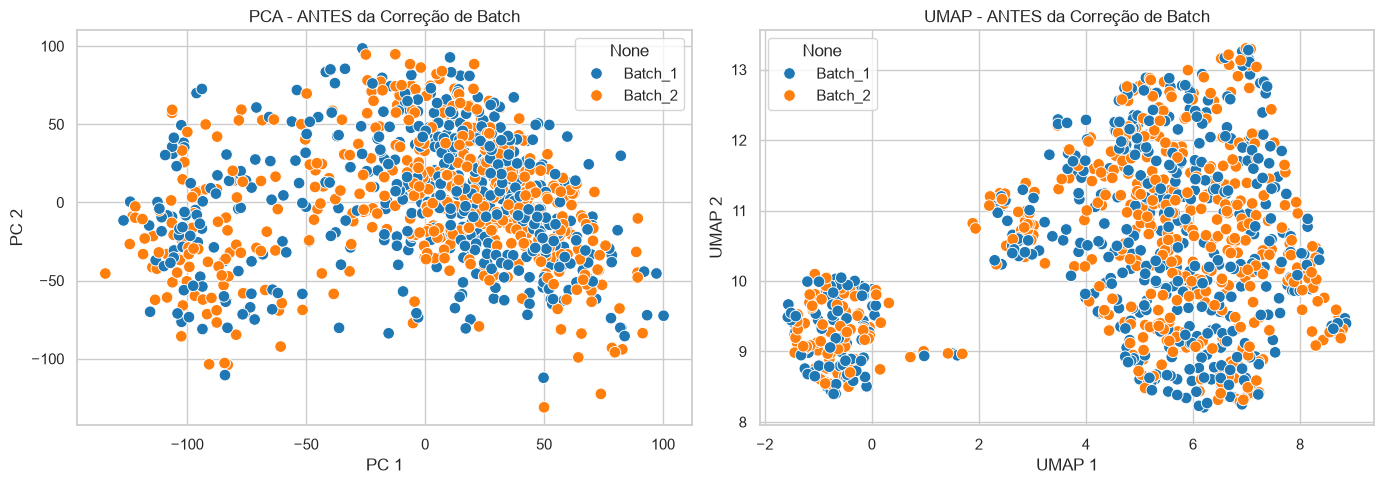


[2/3] Aplicando ComBat para remover o Batch Effect...
Found 2 batches.
Adjusting for 0 covariate(s) or covariate level(s).
Standardizing Data across genes.
Fitting L/S model and finding priors.
Finding parametric adjustments.
Adjusting the Data

[3/3] Gerando visualizações APÓS a correção de Batch...


d:\Projetos Python\Mestrado\RBras\.venv-1\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


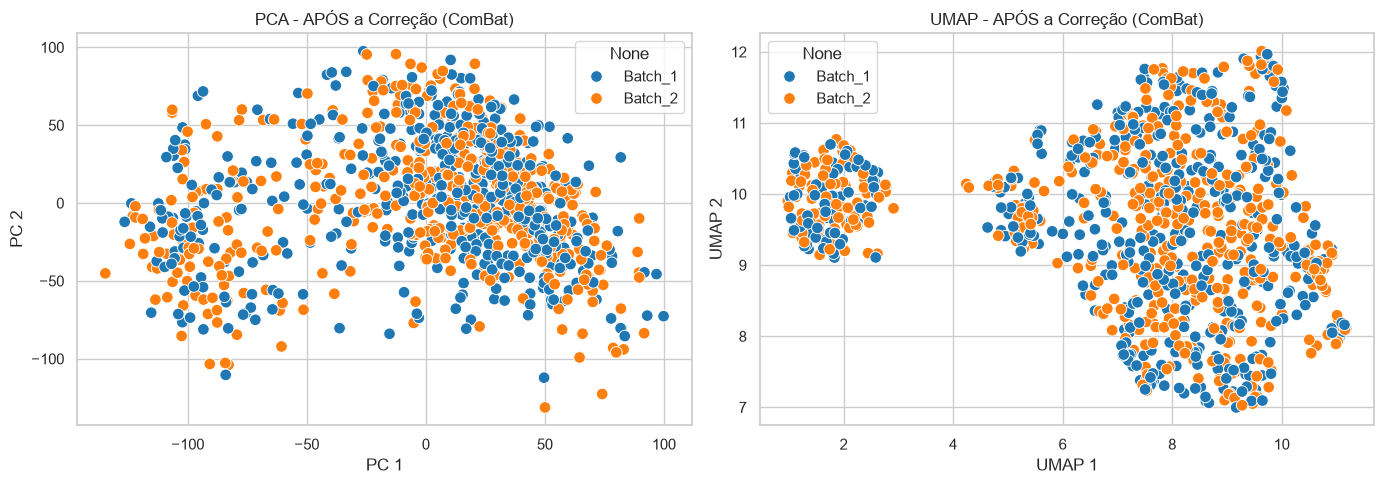

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import umap
from combat.pycombat import pycombat

# Set de estilo visual para os gráficos
sns.set_theme(style="whitegrid")

def analyze_and_correct_batch_effect(
    df_vst: pd.DataFrame,
    batch_info: pd.Series,
    condition_info: pd.Series = None,
    n_components_pca: int = 2
):
    """
    Analisa a presença de Batch Effect via PCA e UMAP antes e depois da correção por ComBat.
    
    Parâmetros:
    -----------
    df_vst : pd.DataFrame
        Matriz VST com Amostras nas LINHAS e Genes nas COLUNAS.
    batch_info : pd.Series
        Série/coluna indicando o Lote/Batch de cada amostra (Index deve bater com as amostras).
    condition_info : pd.Series, optional
        Série/coluna com o Grupo Biológico/Subtipo (para garantir que a biologia seja preservada).
    n_components_pca : int, default=2
        Componentes principais para visualização.
        
    Retorna:
    --------
    pd.DataFrame
        Matriz VST com o Batch Effect corrigido pelo ComBat (Amostras nas Linhas, Genes nas Colunas).
    """
    # 1. Alinhamento de índices
    common_samples = df_vst.index.intersection(batch_info.index)
    df_vst = df_vst.loc[common_samples]
    batch_info = batch_info.loc[common_samples]
    
    if condition_info is not None:
        condition_info = condition_info.loc[common_samples]

    print(f"Dimensão da base VST: {df_vst.shape[0]} amostras x {df_vst.shape[1]} genes")
    print(f"Lotes identificados: {batch_info.unique().tolist()}")

    # =========================================================================
    # ETAPA 1: VISUALIZAÇÃO PRÉ-CORREÇÃO (PCA & UMAP)
    # =========================================================================
    print("\n[1/3] Gerando visualizações ANTES da correção de Batch...")
    
    # PCA Pré-correção
    pca_pre = PCA(n_components=n_components_pca, random_state=42)
    pca_pre_res = pca_pre.fit_transform(df_vst.values)
    
    # UMAP Pré-correção (parâmetros default)
    reducer_pre = umap.UMAP(random_state=42)
    umap_pre_res = reducer_pre.fit_transform(df_vst.values)

    # Plotting Pré-Correção
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    sns.scatterplot(
        x=pca_pre_res[:, 0], y=pca_pre_res[:, 1], 
        hue=batch_info, style=condition_info, ax=axes[0], s=70, palette="tab10"
    )
    axes[0].set_title("PCA - ANTES da Correção de Batch")
    axes[0].set_xlabel("PC 1")
    axes[0].set_ylabel("PC 2")
    
    sns.scatterplot(
        x=umap_pre_res[:, 0], y=umap_pre_res[:, 1], 
        hue=batch_info, style=condition_info, ax=axes[1], s=70, palette="tab10"
    )
    axes[1].set_title("UMAP - ANTES da Correção de Batch")
    axes[1].set_xlabel("UMAP 1")
    axes[1].set_ylabel("UMAP 2")
    
    plt.tight_layout()
    plt.show()

    # =========================================================================
    # ETAPA 2: APLICAÇÃO DO COMBAT (CORREÇÃO DE BATCH EFFECT)
    # =========================================================================
    print("\n[2/3] Aplicando ComBat para remover o Batch Effect...")
    
    # pycombat espera os genes nas LINHAS e amostras nas COLUNAS
    df_vst_T = df_vst.T
    
    # Aplicação do ComBat (com informação biológica opcional para preservar variação biológica)
    if condition_info is not None:
        df_corrected_T = pycombat(df_vst_T, batch_info, mod=pd.get_dummies(condition_info, drop_first=True))
    else:
        df_corrected_T = pycombat(df_vst_T, batch_info)
        
    # Retornar ao formato original: Amostras nas Linhas, Genes nas Colunas
    df_vst_corrected = df_corrected_T.T

    # =========================================================================
    # ETAPA 3: VISUALIZAÇÃO PÓS-CORREÇÃO (PCA & UMAP)
    # =========================================================================
    print("\n[3/3] Gerando visualizações APÓS a correção de Batch...")
    
    # PCA Pós-correção
    pca_post = PCA(n_components=n_components_pca, random_state=42)
    pca_post_res = pca_post.fit_transform(df_vst_corrected.values)
    
    # UMAP Pós-correção
    reducer_post = umap.UMAP(random_state=42)
    umap_post_res = reducer_post.fit_transform(df_vst_corrected.values)

    # Plotting Pós-Correção
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    sns.scatterplot(
        x=pca_post_res[:, 0], y=pca_post_res[:, 1], 
        hue=batch_info, style=condition_info, ax=axes[0], s=70, palette="tab10"
    )
    axes[0].set_title("PCA - APÓS a Correção (ComBat)")
    axes[0].set_xlabel("PC 1")
    axes[0].set_ylabel("PC 2")
    
    sns.scatterplot(
        x=umap_post_res[:, 0], y=umap_post_res[:, 1], 
        hue=batch_info, style=condition_info, ax=axes[1], s=70, palette="tab10"
    )
    axes[1].set_title("UMAP - APÓS a Correção (ComBat)")
    axes[1].set_xlabel("UMAP 1")
    axes[1].set_ylabel("UMAP 2")
    
    plt.tight_layout()
    plt.show()

    return df_vst_corrected


# =========================================================================
# EXEMPLO DE USO INTEGRADO NO SEU PIPELINE:
# =========================================================================
if __name__ == "__main__":
    # 1. Carregar base VST pós-QC (Linhas = Amostras, Colunas = Genes)
    df_vst = pd.read_csv("D:\Projetos Python\Mestrado\RBras\data\processed\df_vst.csv", index_col=0)
    
    # 2. Carregar Metadados com a coluna 'batch' e opcionalmente 'subtipo'
    # metadata = pd.read_csv("data/processed/metadata.csv", index_col=0)
    # batch_info = metadata['batch_id']
    # condition_info = metadata['subtipo_tumoral'] # Se disponível
    
    # SIMULAÇÃO DE METADADOS (substitua pelas colunas reais do seu dataset):
    np.random.seed(42)
    batch_info = pd.Series(
        np.random.choice(["Batch_1", "Batch_2"], size=df_vst.shape[0]),
        index=df_vst.index
    )
    
    # 3. Executar Análise e Correção
    df_vst_corrected = analyze_and_correct_batch_effect(
        df_vst=df_vst,
        batch_info=batch_info,
        condition_info=None # Passe condition_info se tiver os grupos biológicos
    )
    
    # 4. Salvar matriz corrigida para seguir para o MAD (3000 genes) -> PCA (50) -> PaCMAP -> GMM
    # df_vst_corrected.to_csv("data/processed/df_vst_batch_corrected.csv")

In [4]:
import requests
import pandas as pd

def get_tcga_batch_info(patient_ids):
    """
    Busca as informações de lote (Plate ID) na API do GDC para uma lista de pacientes.
    """
    url = "https://api.gdc.cancer.gov/cases"
    
    # Prepara o filtro para buscar os pacientes
    filters = {
        "op": "in",
        "content": {
            "field": "submitter_id",
            "value": patient_ids
        }
    }
    
    params = {
        "filters": pd.io.json.dumps(filters) if hasattr(pd.io, 'json') else str(filters).replace("'", '"'),
        "fields": "submitter_id,samples.portions.analytes.aliquots.submitter_id",
        "format": "JSON",
        "size": len(patient_ids)
    }
    
    response = requests.get(url, params=params)
    data = response.json()
    
    batch_map = {}
    for case in data['data']['hits']:
        patient = case['submitter_id']
        try:
            # Pega o primeiro barcode de alíquota completo para extrair o Plate ID (6º elemento)
            full_barcode = case['samples'][0]['portions'][0]['analytes'][0]['aliquots'][0]['submitter_id']
            plate_id = full_barcode.split('-')[5]
            batch_map[patient] = plate_id
        except (KeyError, IndexError):
            batch_map[patient] = None
            
    return pd.Series(batch_map, name="batch_id")

# Exemplo de uso:
# meupacientes = ["TCGA-3C-AAAU", "TCGA-3C-AALI"]
# batch_info = get_tcga_batch_info(meupacientes)

In [5]:
# Supondo que você baixou a tabela oficial de lotes do TCGA
df_batches = pd.read_csv("TCGA_BRCA_batch_info.txt", sep="\t", index_col=0)

# Faz o mapeamento com base no ID do paciente (TCGA-3C-AAAU)
batch_series = df_vst.index.map(df_batches['BatchId'])

FileNotFoundError: [Errno 2] No such file or directory: 'TCGA_BRCA_batch_info.txt'

In [8]:
import json
import requests
import pandas as pd

def fetch_tcga_batches_from_api(patient_ids, chunk_size=100):
    """
    Busca o ID da Placa (Plate ID / Batch) na API do GDC enviando requisições 
    POST em lotes (chunks) para evitar o erro 414 (Request-URI Too Large).
    """
    patient_ids = list(patient_ids)
    total_patients = len(patient_ids)
    print(f"Buscando informações de lote para {total_patients} pacientes via API do GDC (POST em lotes)...")
    
    url = "https://api.gdc.cancer.gov/cases"
    batch_dict = {}

    # Iterar sobre a lista de pacientes em blocos de tamanho 'chunk_size'
    for i in range(0, total_patients, chunk_size):
        chunk = patient_ids[i:i + chunk_size]
        
        filters = {
            "op": "in",
            "content": {
                "field": "submitter_id",
                "value": chunk
            }
        }
        
        payload = {
            "filters": filters,
            "fields": "submitter_id,samples.portions.analytes.aliquots.submitter_id",
            "format": "JSON",
            "size": len(chunk)
        }
        
        response = requests.post(url, json=payload)
        
        if response.status_code != 200:
            print(f"Aviso: Falha no lote {i} a {i+len(chunk)} (Status {response.status_code})")
            continue
            
        data = response.json()
        
        for case in data.get('data', {}).get('hits', []):
            patient = case.get('submitter_id')
            try:
                # Extrai o barcode completo e recupera o 6º elemento (Plate ID / Lote)
                full_barcode = case['samples'][0]['portions'][0]['analytes'][0]['aliquots'][0]['submitter_id']
                plate_id = full_barcode.split('-')[5]
                batch_dict[patient] = plate_id
            except (KeyError, IndexError):
                batch_dict[patient] = "Unknown"
                
    # Mapeia de volta na ordem original das amostras
    batch_series = pd.Series([batch_dict.get(pid, "Unknown") for pid in patient_ids], index=patient_ids, name="BatchId")
    return batch_series


# ==========================================
# EXECUTAR NO SEU NOTEBOOK:
# ==========================================
patient_list = df_vst.index.tolist()
batch_series = fetch_tcga_batches_from_api(patient_list)

print("\n" + "="*40)
print(" RELATÓRIO DE DISTRIBUIÇÃO DE LOTES ")
print("="*40)
print(batch_series.value_counts())

Buscando informações de lote para 970 pacientes via API do GDC (POST em lotes)...

 RELATÓRIO DE DISTRIBUIÇÃO DE LOTES 
BatchId
A12U    23
A10H    23
A14O    18
A14R    17
A097    14
        ..
A32T     1
A706     1
A36F     1
A41G     1
A36I     1
Name: count, Length: 276, dtype: int64


d:\Projetos Python\Mestrado\RBras\.venv-1\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


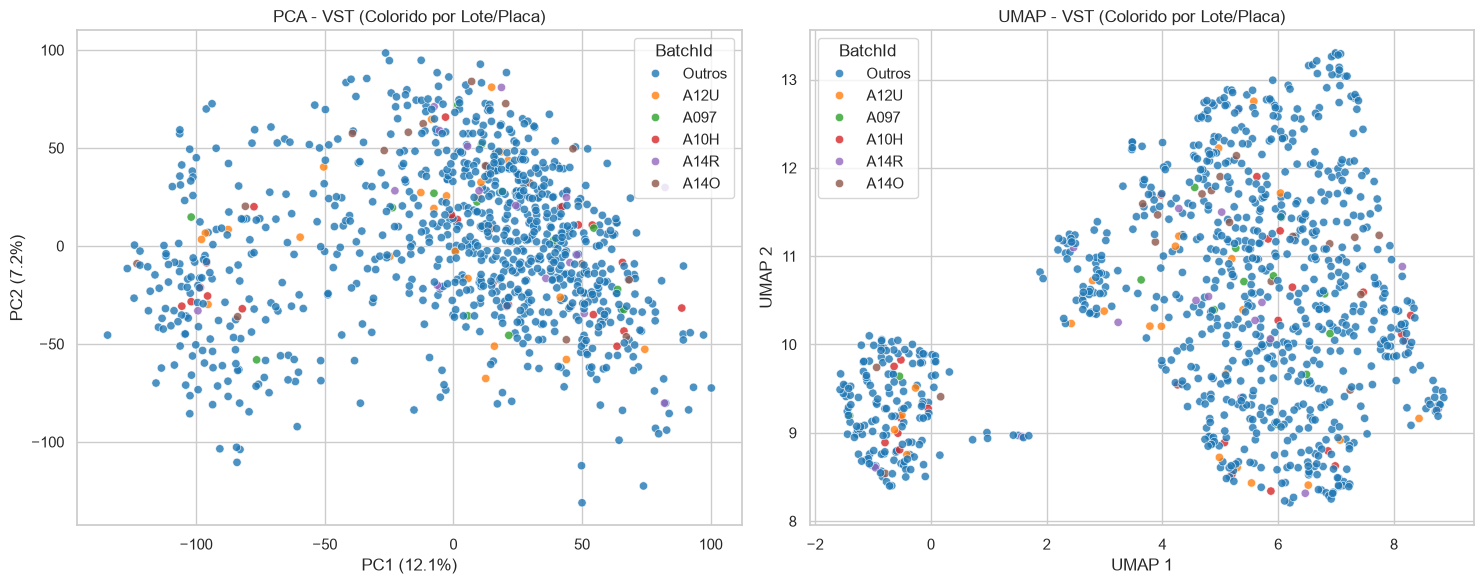

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import umap

# 1. Alinhar o batch_series com as amostras da df_vst
common_samples = df_vst.index.intersection(batch_series.index)
df_vst_aligned = df_vst.loc[common_samples]
batch_series_aligned = batch_series.loc[common_samples]

# Para o gráfico não ficar poluído com 276 cores, destacamos os 5 maiores lotes e agrupamos o restante como 'Outros'
top_batches = batch_series_aligned.value_counts().nlargest(5).index
batch_plot_labels = batch_series_aligned.apply(lambda x: x if x in top_batches else 'Outros')

# 2. Calcular PCA e UMAP
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(df_vst_aligned.values)

reducer = umap.UMAP(random_state=42)
X_umap = reducer.fit_transform(df_vst_aligned.values)

# 3. Plotar
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=batch_plot_labels, ax=axes[0], palette="tab10", alpha=0.8)
axes[0].set_title("PCA - VST (Colorido por Lote/Placa)")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")

sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=batch_plot_labels, ax=axes[1], palette="tab10", alpha=0.8)
axes[1].set_title("UMAP - VST (Colorido por Lote/Placa)")
axes[1].set_xlabel("UMAP 1")
axes[1].set_ylabel("UMAP 2")

plt.tight_layout()
plt.show()

## Tratar com ComBat

In [10]:
from combat.pycombat import pycombat

# Identifica lotes com pelo menos 2 amostras
counts = batch_series_aligned.value_counts()
valid_batches = counts[counts >= 2].index

# Filtra o DataFrame e a série de lotes para manter apenas amostras de lotes com >= 2 amostras
valid_samples = batch_series_aligned[batch_series_aligned.isin(valid_batches)].index

df_vst_for_combat = df_vst_aligned.loc[valid_samples]
batch_for_combat = batch_series_aligned.loc[valid_samples]

print(f"Amostras mantidas para o ComBat (lotes com n >= 2): {len(valid_samples)} de {len(df_vst_aligned)}")

# Executa o ComBat (pycombat espera genes nas LINHAS e amostras nas COLUNAS)
df_vst_T = df_vst_for_combat.T
df_vst_corrected_T = pycombat(df_vst_T, batch_for_combat)

# Retorna para o formato (Amostras nas Linhas, Genes nas Colunas)
df_vst_corrected = df_vst_corrected_T.T

print("Correção de Batch Effect concluída com sucesso!")

Amostras mantidas para o ComBat (lotes com n >= 2): 871 de 970
Found 177 batches.
Adjusting for 0 covariate(s) or covariate level(s).
Standardizing Data across genes.
Fitting L/S model and finding priors.
Finding parametric adjustments.


d:\Projetos Python\Mestrado\RBras\.venv-1\Lib\site-packages\combat\pycombat.py:159: RuntimeWarning: divide by zero encountered in divide
  np.absolute(d_new-d_old)/d_old))  # maximum difference between new and old estimate


Adjusting the Data
Correção de Batch Effect concluída com sucesso!



[Passo 3] Gerando visualizações APÓS a correção de Batch (ComBat)...


d:\Projetos Python\Mestrado\RBras\.venv-1\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


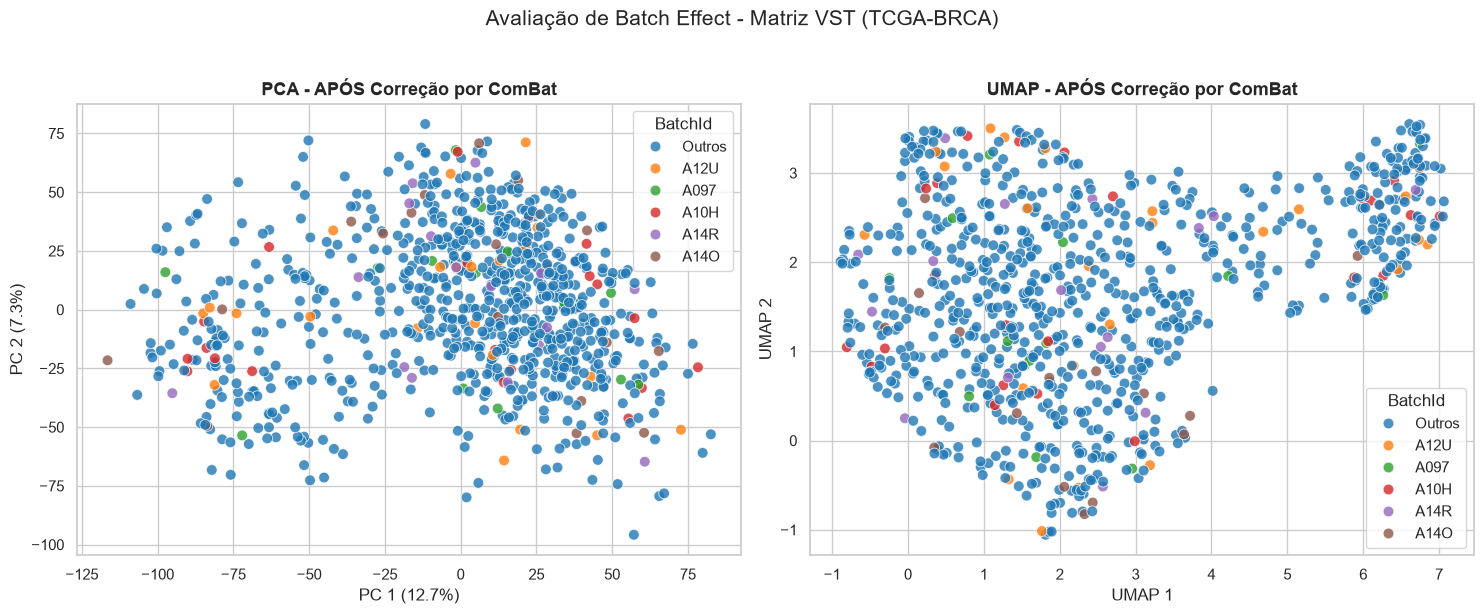

OSError: Cannot save file into a non-existent directory: 'data\processed'

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import umap

# Configuração visual do seaborn
sns.set_theme(style="whitegrid")

# =========================================================================
# PASSO 3: VISUALIZAÇÃO E AVALIAÇÃO PÓS-CORREÇÃO DE BATCH (ComBat)
# =========================================================================

print("\n[Passo 3] Gerando visualizações APÓS a correção de Batch (ComBat)...")

# 1. Alinhamento final das amostras entre a base corrigida e os metadados de lote
valid_samples = df_vst_corrected.index
batch_series_post = batch_series.loc[valid_samples]

# Destacar os 5 maiores lotes para o plot não ficar poluído (mantém padrão do Passo 1)
top_batches = batch_series_post.value_counts().nlargest(5).index
batch_plot_labels_post = batch_series_post.apply(lambda x: x if x in top_batches else 'Outros')

# 2. Redução de Dimensionalidade Pós-Correção (PCA & UMAP)
pca_post = PCA(n_components=2, random_state=42)
X_pca_post = pca_post.fit_transform(df_vst_corrected.values)

reducer_post = umap.UMAP(random_state=42)
X_umap_post = reducer_post.fit_transform(df_vst_corrected.values)

# 3. Construção dos Gráficos Comparativos Pós-Correção
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot PCA Pós-ComBat
sns.scatterplot(
    x=X_pca_post[:, 0], 
    y=X_pca_post[:, 1], 
    hue=batch_plot_labels_post, 
    ax=axes[0], 
    palette="tab10", 
    alpha=0.8, 
    s=60
)
axes[0].set_title("PCA - APÓS Correção por ComBat", fontsize=13, fontweight='bold')
axes[0].set_xlabel(f"PC 1 ({pca_post.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC 2 ({pca_post.explained_variance_ratio_[1]*100:.1f}%)")

# Plot UMAP Pós-ComBat
sns.scatterplot(
    x=X_umap_post[:, 0], 
    y=X_umap_post[:, 1], 
    hue=batch_plot_labels_post, 
    ax=axes[1], 
    palette="tab10", 
    alpha=0.8, 
    s=60
)
axes[1].set_title("UMAP - APÓS Correção por ComBat", fontsize=13, fontweight='bold')
axes[1].set_xlabel("UMAP 1")
axes[1].set_ylabel("UMAP 2")

plt.suptitle("Avaliação de Batch Effect - Matriz VST (TCGA-BRCA)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# 4. Salvar a matriz VST corrigida no disco para continuar o pipeline (MAD -> PCA 50 -> PaCMAP -> GMM)
df_vst_corrected.to_csv("data/processed/df_vst_batch_corrected.csv")
print("Matriz VST corrigida salva em 'data/processed/df_vst_batch_corrected.csv'")